# Step 7.c -- SVM prediction sensitivity to a shifted crop calendar (ERA5 ref + ISIMIP 2061-2080 future)

Consumes [7.a)](../7.a\)_Build_BIOvariables_shifted_calendar_ERA5/7.a\)_Build_BIOvariables_shifted_calendar_ERA5.ipynb)
(ERA5 reference) and [7.b)](../7.b\)_Build_BIOvariables_futures/ISIMIP_2061_2080/7.b\)_BIOvariables_futures_ISIMIP_2061_2080.ipynb)
(ISIMIP future), each already computed at 5 calendar shifts ({-60,-50,...,0,...,+50,+60} days).

**No retraining anywhere in this notebook.** The already-trained no-threshold model
(`3.d)_SVM_train_ERA5_MIRCA2000_no_threshold`) is loaded once and reused unchanged for
every shift -- it only ever sees BIO01-12 values and is calendar-agnostic by construction
(see the discussion that preceded `7.a)`). For each shift, the SAME shift is applied to
BOTH the ERA5 reference and the ISIMIP future BIO variables before scoring (**Option B**
from the 2026-10-19 discussion) -- this isolates the model's sensitivity to the averaging
window itself, keeping the reference/future comparison apples-to-apples at every shift,
rather than asking a different question (asymmetric future-only adaptation).

Answers: how much does the SVM's projected climate-only suitable area for Maize_rf (ERA5
1981-2015 -> ISIMIP MRI-ESM2-0 SSP585 2061-2080) change if the growing season used to
average climate were uniformly shifted by up to +-60 days from MIRCA2000's historical
calendar? Directly addresses the fixed-calendar limitation flagged in Section 6 of
`Crop_Suitability_SVM_Report.docx`.

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')

BASE    = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
DIR_7A  = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.a)_Build_BIOvariables_shifted_calendar_ERA5"
DIR_7B  = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.b)_Build_BIOvariables_futures" / "ISIMIP_2061_2080"
MDL_DIR = BASE / "1_SVM" / "3_SVM_train" / "3.d)_SVM_train_ERA5_MIRCA2000_no_threshold" / "svm_train_outputs_mirca2000_no_threshold"
OUT_DIR = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.c)_SVM_predict_shifted_calendar_sensitivity" / "out"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CROP_LABEL = 'Maize_rf'
THRESHOLD  = 0.5
SHIFTS     = [-60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60]

def shift_tag(d):
    return 'cal' + ('0' if d == 0 else ('P' if d > 0 else 'M') + str(abs(d)))

mdl_path = MDL_DIR / f'svm_model_{CROP_LABEL}.joblib'
print(f'{"OK" if mdl_path.exists() else "MISSING"}: {mdl_path}')
for d in SHIFTS:
    rp = DIR_7A / f'out_{shift_tag(d)}' / f'BIO_{CROP_LABEL}_{shift_tag(d)}.nc'
    fp = DIR_7B / f'out_{shift_tag(d)}' / f'BIO_{CROP_LABEL}_{shift_tag(d)}.nc'
    print(f'  shift {d:+d}d: {"OK" if rp.exists() else "MISSING"} ref | {"OK" if fp.exists() else "MISSING"} fut')

OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\3_SVM_train\3.d)_SVM_train_ERA5_MIRCA2000_no_threshold\svm_train_outputs_mirca2000_no_threshold\svm_model_Maize_rf.joblib
  shift -60d: OK ref | OK fut
  shift -50d: OK ref | OK fut
  shift -40d: OK ref | OK fut
  shift -30d: OK ref | OK fut
  shift -20d: OK ref | OK fut
  shift -10d: OK ref | OK fut
  shift +0d: OK ref | OK fut
  shift +10d: OK ref | OK fut
  shift +20d: OK ref | OK fut
  shift +30d: OK ref | OK fut
  shift +40d: OK ref | OK fut
  shift +50d: OK ref | OK fut
  shift +60d: OK ref | OK fut


## 1. Load model (frozen, no retraining)

In [2]:
bundle = joblib.load(mdl_path)
print(f'Model   : cost={bundle["best_cost"]}, gamma={bundle["best_gamma"]}')
print(f'Trained : {bundle["n_class1"]} presence + {bundle["n_class0"]} background pixels (ERA5 1981-2015, no-threshold)')

# grid from the cal0 (unshifted) ERA5 reference file
ds0 = xr.open_dataset(DIR_7A / 'out_cal0' / f'BIO_{CROP_LABEL}_cal0.nc')
lats, lons = ds0.lat.values, ds0.lon.values
nlat, nlon = len(lats), len(lons)
ds0.close()
print(f'Grid    : {nlat} lat x {nlon} lon')

R_earth = 6371.0
lat_area_km2   = (1.0 * np.pi / 180 * R_earth) ** 2 * np.cos(np.radians(lats))
pixel_area_km2 = np.tile(lat_area_km2[:, None], (1, nlon))
pixel_area_Mha = pixel_area_km2 * 100 / 1e6


def predict_suitability(nc_path, bundle):
    """Same pattern as 4.f.bis)/4.1) -- frozen scaler+model, no retraining."""
    ds = xr.open_dataset(nc_path)
    X_2d = np.stack([ds[col].values for col in bundle['bio_cols']], axis=-1)
    ds.close()
    X_flat = X_2d.reshape(-1, len(bundle['bio_cols']))
    valid = ~np.any(np.isnan(X_flat), axis=1)
    suit = np.full(nlat * nlon, np.nan)
    if valid.any():
        X_sc = bundle['scaler'].transform(X_flat[valid])
        suit[valid] = bundle['model'].predict_proba(X_sc)[:, 1]
    return suit.reshape(nlat, nlon)


def suitable_area_Mha(bin_arr):
    mask = (bin_arr == 1) & ~np.isnan(bin_arr)
    return float(np.nansum(pixel_area_Mha[mask]))

print('Functions defined.')

Model   : cost=16.0, gamma=0.1
Trained : 979 presence + 353 background pixels (ERA5 1981-2015, no-threshold)


Grid    : 37 lat x 70 lon
Functions defined.


In [3]:
import regionmask

def draw_land_ocean_bg(ax, ext, _cache={}):
    """Ocean in gray, land left white, at a finer resolution (0.1deg) than our 1deg data
    so the coastline reads as an actual map rather than our own blocky grid. Drawn first
    (zorder=0); the real data imshow'd on top leaves NaN/background pixels transparent by
    matplotlib's default, so the land/ocean outline shows through everywhere there's no
    data (ocean cells, and e.g. the 'never suitable under any shift' masked pixels)."""
    if 'land_bg' not in _cache:
        fine_lons = np.arange(ext[0], ext[1] + 0.001, 0.1)
        fine_lats = np.arange(ext[2], ext[3] + 0.001, 0.1)
        countries_rg = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
        # .mask() has a library bug at this fine a resolution (regionmask 0.13.0,
        # AttributeError in flag_meanings construction) -- .mask_3D() avoids that codepath
        mask3d = countries_rg.mask_3D(fine_lons, fine_lats)
        _cache['land_bg'] = mask3d.any(dim='region').values
        _cache['fine_ext'] = ext
    land_bg = _cache['land_bg']
    from matplotlib.colors import ListedColormap
    cmap_bg = ListedColormap(['#b0b0b0', '#ffffff'])  # ocean=gray, land=white
    ax.imshow(land_bg.astype(float), origin='lower', aspect='auto',
              extent=_cache['fine_ext'], cmap=cmap_bg, vmin=0, vmax=1, zorder=0)

print('draw_land_ocean_bg defined (regionmask, 0.1deg background).')

draw_land_ocean_bg defined (regionmask, 0.1deg background).


## 2. Loop over shifts -- score ERA5 ref AND ISIMIP fut with the SAME shift, same frozen model

Option B (2026-10-19 decision): both sides of the comparison use the same calendar shift at
each step, so the ref-vs-fut comparison (`change_cat`, areas) stays apples-to-apples with the
original (shift=0) Table 4-style numbers -- only the averaging window moves, not the model.

In [4]:
rows = []
change_cat_by_shift = {}
suit_ref_by_shift = {}   # raw P(suitable), per shift -- for the adaptive/union analysis below
suit_fut_by_shift = {}

for d in SHIFTS:
    tag = shift_tag(d)
    ref_nc = DIR_7A / f'out_{tag}' / f'BIO_{CROP_LABEL}_{tag}.nc'
    fut_nc = DIR_7B / f'out_{tag}' / f'BIO_{CROP_LABEL}_{tag}.nc'

    suit_ref = predict_suitability(ref_nc, bundle)
    suit_fut = predict_suitability(fut_nc, bundle)
    suit_ref_by_shift[d] = suit_ref
    suit_fut_by_shift[d] = suit_fut
    suit_ref_bin = np.where(np.isnan(suit_ref), np.nan, (suit_ref >= THRESHOLD).astype(float))
    suit_fut_bin = np.where(np.isnan(suit_fut), np.nan, (suit_fut >= THRESHOLD).astype(float))

    valid_mask = ~np.isnan(suit_ref_bin) & ~np.isnan(suit_fut_bin)
    change_cat = np.full((nlat, nlon), np.nan)
    change_cat[valid_mask & (suit_ref_bin == 0) & (suit_fut_bin == 0)] = 0
    change_cat[valid_mask & (suit_ref_bin == 0) & (suit_fut_bin == 1)] = 1
    change_cat[valid_mask & (suit_ref_bin == 1) & (suit_fut_bin == 1)] = 2
    change_cat[valid_mask & (suit_ref_bin == 1) & (suit_fut_bin == 0)] = 3
    change_cat_by_shift[d] = change_cat

    area_ref  = suitable_area_Mha(np.where(valid_mask, suit_ref_bin, np.nan))
    area_fut  = suitable_area_Mha(np.where(valid_mask, suit_fut_bin, np.nan))
    area_gain = suitable_area_Mha((change_cat == 1).astype(float))
    area_loss = suitable_area_Mha((change_cat == 3).astype(float))
    net_pct   = 100 * (area_fut - area_ref) / area_ref if area_ref > 0 else np.nan

    n_total = int(valid_mask.sum())
    rows.append({
        'shift_days': d, 'n_comparable_pixels': n_total,
        'area_ref_Mha': area_ref, 'area_fut_Mha': area_fut,
        'area_gain_Mha': area_gain, 'area_loss_Mha': area_loss,
        'net_change_pct': net_pct,
    })
    print(f'shift={d:+3d}d  ref={area_ref:7.2f} Mha  fut={area_fut:7.2f} Mha  '
          f'gain={area_gain:6.2f}  loss={area_loss:6.2f}  net={net_pct:+6.1f}%')

df_sens = pd.DataFrame(rows)
out_csv = OUT_DIR / f'sensitivity_{CROP_LABEL}.csv'
df_sens.to_csv(out_csv, index=False)
print(f'\nSaved: {out_csv}')
df_sens

shift=-60d  ref= 695.22 Mha  fut= 778.37 Mha  gain=187.55  loss=104.40  net= +12.0%


shift=-50d  ref= 700.41 Mha  fut= 816.33 Mha  gain=174.35  loss= 58.43  net= +16.6%


shift=-40d  ref= 705.20 Mha  fut= 827.73 Mha  gain=139.72  loss= 17.20  net= +17.4%


shift=-30d  ref= 754.29 Mha  fut= 846.00 Mha  gain=124.10  loss= 32.38  net= +12.2%


shift=-20d  ref= 785.05 Mha  fut= 871.09 Mha  gain=115.03  loss= 28.98  net= +11.0%


...

shift=+30d  ref= 792.88 Mha  fut= 901.66 Mha  gain=125.65  loss= 16.88  net= +13.7%


shift=+40d  ref= 780.81 Mha  fut= 896.51 Mha  gain=131.85  loss= 16.14  net= +14.8%


shift=+50d  ref= 816.46 Mha  fut= 916.82 Mha  gain=135.43  loss= 35.07  net= +12.3%


shift=+60d  ref= 763.68 Mha  fut= 935.82 Mha  gain=205.35  loss= 33.21  net= +22.5%

Saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\7_test_adaptable_calendar\7.c)_SVM_predict_shifted_calendar_sensitivity\out\sensitivity_Maize_rf.csv


,shift_days,n_comparable_pixels,area_ref_Mha,area_fut_Mha,area_gain_Mha,area_loss_Mha,net_change_pct
0,-60,1332,695.224236,778.369473,187.545983,104.400745,11.959485
1,-50,1332,700.408533,816.334204,174.353876,58.428206,16.551151
2,-40,1332,705.203093,827.731098,139.723095,17.195090,17.374854
3,-30,1332,754.288156,846.000124,124.095729,32.383760,12.158744
4,-20,1332,785.045738,871.092507,115.025145,28.978376,10.960733
5,-10,1332,806.044380,891.022017,107.888984,22.911348,10.542551
6,0,1332,796.334561,898.578198,125.106425,22.862788,12.839282
7,10,1332,805.185286,890.793754,122.374844,36.766375,10.632145
8,20,1332,792.716014,894.239609,135.224690,33.701094,12.807057
9,30,1332,792.884595,901.658720,125.652827,16.878702,13.718784


## 3. Sensitivity plot -- suitable area (ref and fut) vs calendar shift

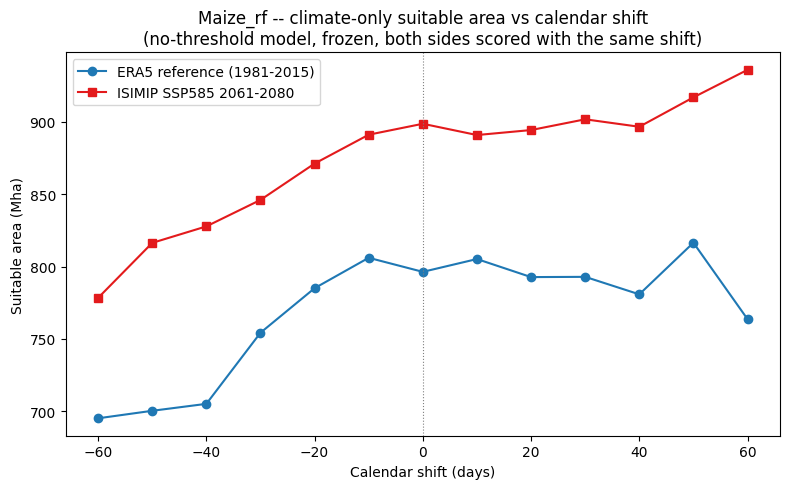

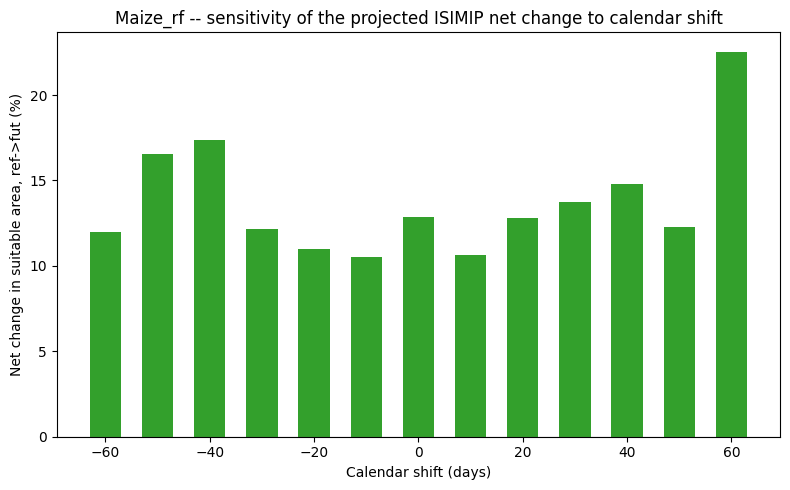

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df_sens['shift_days'], df_sens['area_ref_Mha'], 'o-', label='ERA5 reference (1981-2015)', color='#1f78b4')
ax.plot(df_sens['shift_days'], df_sens['area_fut_Mha'], 's-', label='ISIMIP SSP585 2061-2080', color='#e31a1c')
ax.set_xlabel('Calendar shift (days)')
ax.set_ylabel('Suitable area (Mha)')
ax.set_title(f'{CROP_LABEL} -- climate-only suitable area vs calendar shift\n(no-threshold model, frozen, both sides scored with the same shift)')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / f'sensitivity_area_{CROP_LABEL}.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(df_sens['shift_days'], df_sens['net_change_pct'], width=6, color='#33a02c')
ax.set_xlabel('Calendar shift (days)')
ax.set_ylabel('Net change in suitable area, ref->fut (%)')
ax.set_title(f'{CROP_LABEL} -- sensitivity of the projected ISIMIP net change to calendar shift')
ax.axhline(0, color='gray', lw=0.8)
plt.tight_layout()
plt.savefig(OUT_DIR / f'sensitivity_netchange_{CROP_LABEL}.png', dpi=150)
plt.show()

## 4. Change-category maps -- the two extreme shifts vs baseline

Visual check that the area-level sensitivity numbers above correspond to a spatially
sensible pattern (not an artifact concentrated in one or two pixels).

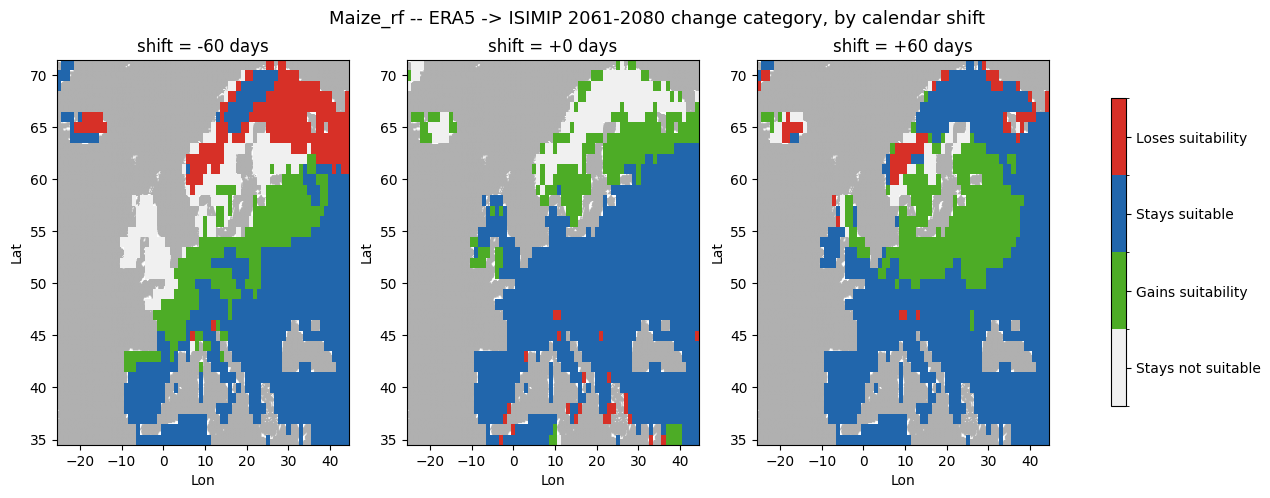

Done.


In [6]:
from matplotlib.colors import ListedColormap, BoundaryNorm
cmap_cc = ListedColormap(['#f0f0f0', '#4dac26', '#2166ac', '#d73027'])
norm_cc = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap_cc.N)
ext = [lons[0] - 0.5, lons[-1] + 0.5, lats[0] - 0.5, lats[-1] + 0.5]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, d in zip(axes, [-60, 0, 60]):
    draw_land_ocean_bg(ax, ext)
    im = ax.imshow(change_cat_by_shift[d], origin='lower', aspect='auto',
                    extent=ext, cmap=cmap_cc, norm=norm_cc, zorder=1)
    ax.set_title(f'shift = {d:+d} days'); ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
cbar = fig.colorbar(im, ax=axes, ticks=[0, 1, 2, 3], shrink=0.8)
cbar.ax.set_yticklabels(['Stays not suitable', 'Gains suitability', 'Stays suitable', 'Loses suitability'])
plt.suptitle(f'{CROP_LABEL} -- ERA5 -> ISIMIP 2061-2080 change category, by calendar shift', fontsize=13)
plt.savefig(OUT_DIR / f'changecat_maps_{CROP_LABEL}.png', dpi=120, bbox_inches='tight')
plt.show()
print('Done.')

## 5. "Adaptable calendar" as additional possibilities, not a fixed re-dating (user's actual question, 2026-10-19)

Section 2-4 above test a **uniform, blind** shift -- the same shift applied to every pixel,
whether or not that direction helps it (e.g. it can push an already-hot Mediterranean pixel
further into heat stress, see the discussion that preceded this section). That is NOT what
"adaptable calendar" is meant to capture.

**What's computed here instead**: for each pixel and each period (ERA5 reference, ISIMIP
future) *independently*, take the **best of the 5 tested shifts** (max probability across
{-60,-50,...,0,...,+50,+60} days) -- i.e. a pixel counts as suitable under the adaptive calendar iff
it is suitable under **at least one** of the tested shifts. This is a union/OR across
possibilities, not an average or a single new fixed assumption, and it can only ever match or
exceed the single-shift (shift=0) baseline area for the SAME period -- taking the max of a set
that includes shift=0 cannot be smaller than shift=0 alone. Still no retraining: the same
frozen model just gets evaluated at 5 different input windows and the best one is kept per
pixel. This is an *upper bound* on what a +-60-day-flexible calendar could achieve (the true
achievable gain for a real farmer is <= this, since 10-day steps are coarser than a truly
continuous choice, and a real farmer cannot re-pick the reference-period calendar after the
fact -- but it directly answers "how many additional climatically-suitable pixels exist
*somewhere* in the +-60-day neighbourhood of today's calendar that the fixed calendar misses?".

In [7]:
suit_ref_adapt = np.nanmax(np.stack([suit_ref_by_shift[d] for d in SHIFTS], axis=0), axis=0)
suit_fut_adapt = np.nanmax(np.stack([suit_fut_by_shift[d] for d in SHIFTS], axis=0), axis=0)
best_shift_ref = np.array(SHIFTS)[np.nanargmax(np.stack([np.nan_to_num(suit_ref_by_shift[d], nan=-1) for d in SHIFTS], axis=0), axis=0)].astype(float)
best_shift_fut = np.array(SHIFTS)[np.nanargmax(np.stack([np.nan_to_num(suit_fut_by_shift[d], nan=-1) for d in SHIFTS], axis=0), axis=0)].astype(float)
nan_mask_ref = np.isnan(suit_ref_by_shift[0])
nan_mask_fut = np.isnan(suit_fut_by_shift[0])
best_shift_ref[nan_mask_ref] = np.nan
best_shift_fut[nan_mask_fut] = np.nan

suit_ref_adapt_bin = np.where(np.isnan(suit_ref_adapt), np.nan, (suit_ref_adapt >= THRESHOLD).astype(float))
suit_fut_adapt_bin = np.where(np.isnan(suit_fut_adapt), np.nan, (suit_fut_adapt >= THRESHOLD).astype(float))

area_ref_adapt = suitable_area_Mha(suit_ref_adapt_bin)
area_fut_adapt = suitable_area_Mha(suit_fut_adapt_bin)
area_ref_fixed = float(df_sens.loc[df_sens.shift_days == 0, 'area_ref_Mha'].iloc[0])
area_fut_fixed = float(df_sens.loc[df_sens.shift_days == 0, 'area_fut_Mha'].iloc[0])

print('=== Fixed (shift=0 only) vs Adaptive (best of +-20d, per pixel) ===')
print(f'ERA5 reference : fixed={area_ref_fixed:7.2f} Mha   adaptive={area_ref_adapt:7.2f} Mha   '
      f'+{area_ref_adapt-area_ref_fixed:6.2f} Mha unlocked ({100*(area_ref_adapt-area_ref_fixed)/area_ref_fixed:+.1f}%)')
print(f'ISIMIP future  : fixed={area_fut_fixed:7.2f} Mha   adaptive={area_fut_adapt:7.2f} Mha   '
      f'+{area_fut_adapt-area_fut_fixed:6.2f} Mha unlocked ({100*(area_fut_adapt-area_fut_fixed)/area_fut_fixed:+.1f}%)')

net_fixed  = 100 * (area_fut_fixed - area_ref_fixed) / area_ref_fixed
net_adapt  = 100 * (area_fut_adapt - area_ref_adapt) / area_ref_adapt
print(f'\nNet change, fixed calendar   : {net_fixed:+.1f}%')
print(f'Net change, adaptive calendar: {net_adapt:+.1f}%')

=== Fixed (shift=0 only) vs Adaptive (best of +-20d, per pixel) ===
ERA5 reference : fixed= 796.33 Mha   adaptive= 966.34 Mha   +170.00 Mha unlocked (+21.3%)
ISIMIP future  : fixed= 898.58 Mha   adaptive= 987.52 Mha   + 88.95 Mha unlocked (+9.9%)

Net change, fixed calendar   : +12.8%
Net change, adaptive calendar: +2.2%


### 5.1 Where does adaptation help, and with which shift?

Pixels never suitable under any tested shift -- ref: 52, fut: 17 (left blank in the maps below, not coloured)


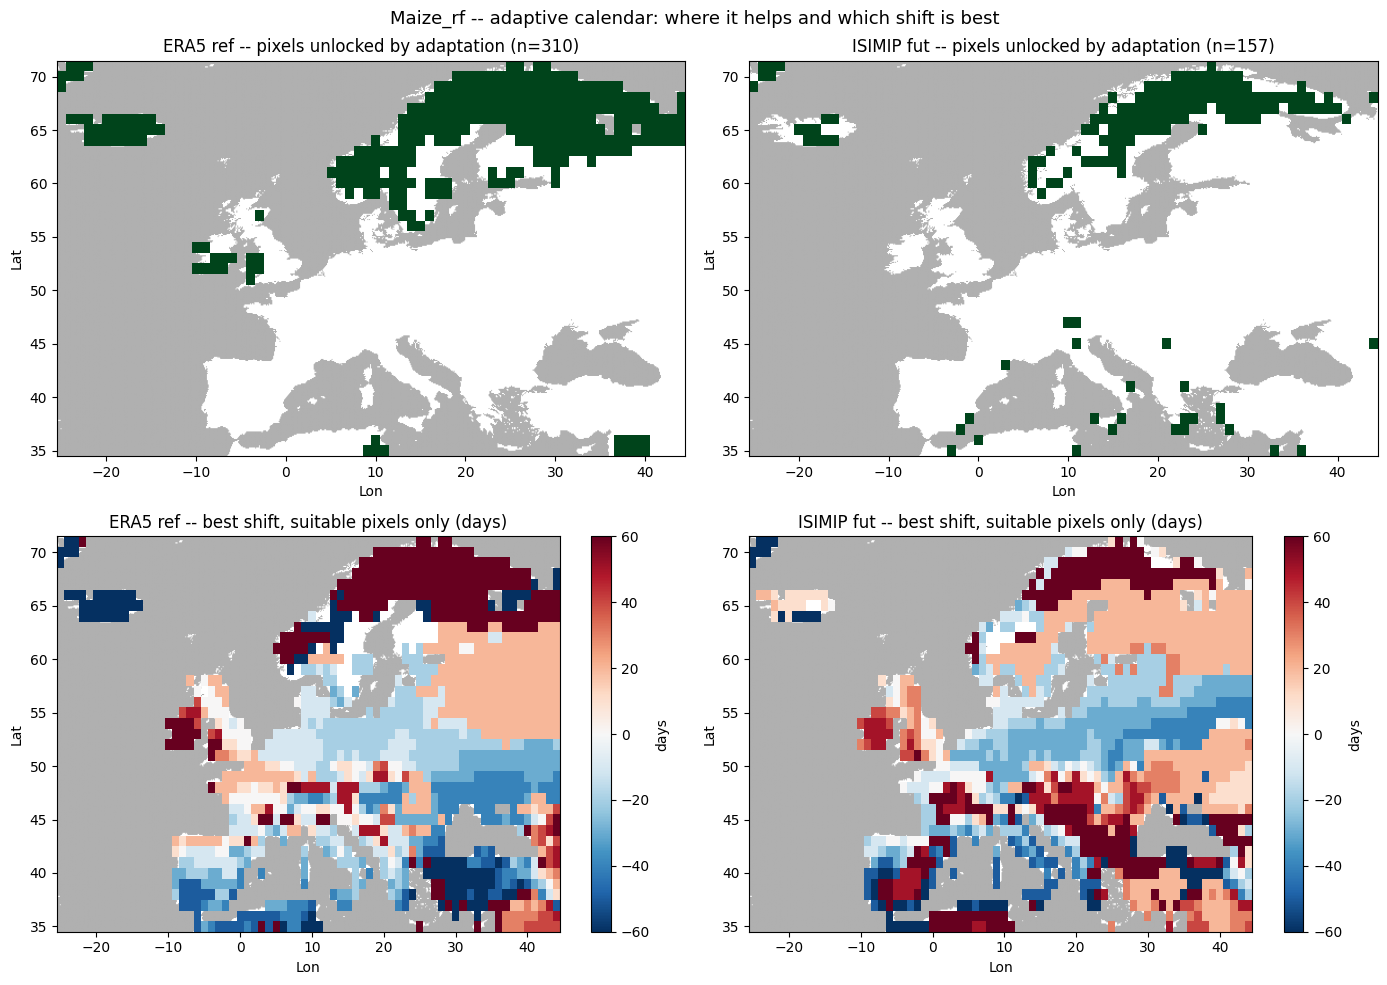

    period  area_fixed_Mha  area_adaptive_Mha  unlocked_Mha  unlocked_pct
  ERA5_ref      796.334561         966.338061    170.003500     21.348251
ISIMIP_fut      898.578198         987.523623     88.945425      9.898462


In [8]:
ext = [lons[0] - 0.5, lons[-1] + 0.5, lats[0] - 0.5, lats[-1] + 0.5]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

gain_ref = (suit_ref_adapt_bin == 1) & (suit_ref_by_shift[0] < THRESHOLD)
gain_fut = (suit_fut_adapt_bin == 1) & (suit_fut_by_shift[0] < THRESHOLD)
gain_ref_plot = np.where(gain_ref, 1.0, np.nan)   # NaN (not 0) so "not unlocked" stays transparent, not green-ish
gain_fut_plot = np.where(gain_fut, 1.0, np.nan)
draw_land_ocean_bg(axes[0,0], ext); draw_land_ocean_bg(axes[0,1], ext)
im0 = axes[0,0].imshow(gain_ref_plot, origin='lower', aspect='auto', extent=ext, cmap='Greens', vmin=0, vmax=1, zorder=1)
axes[0,0].set_title(f'ERA5 ref -- pixels unlocked by adaptation (n={int(np.nansum(gain_ref))})')
im1 = axes[0,1].imshow(gain_fut_plot, origin='lower', aspect='auto', extent=ext, cmap='Greens', vmin=0, vmax=1, zorder=1)
axes[0,1].set_title(f'ISIMIP fut -- pixels unlocked by adaptation (n={int(np.nansum(gain_fut))})')

# Mask to pixels that are suitable under AT LEAST ONE tested shift -- elsewhere the
# argmax is picking among near-zero probabilities (caught by the user: 279/1332 land
# pixels never cross THRESHOLD under any shift, median best proba there is 0.035), so the
# 'best shift' would be meaningless noise, not a real agronomic signal, if shown.
best_shift_ref_masked = np.where(suit_ref_adapt_bin == 1, best_shift_ref, np.nan)
best_shift_fut_masked = np.where(suit_fut_adapt_bin == 1, best_shift_fut, np.nan)
n_never_ref = int(np.nansum((suit_ref_adapt_bin == 0)))
n_never_fut = int(np.nansum((suit_fut_adapt_bin == 0)))
print(f'Pixels never suitable under any tested shift -- ref: {n_never_ref}, fut: {n_never_fut} '
      f'(left blank in the maps below, not coloured)')

draw_land_ocean_bg(axes[1,0], ext); draw_land_ocean_bg(axes[1,1], ext)
im2 = axes[1,0].imshow(best_shift_ref_masked, origin='lower', aspect='auto', extent=ext, cmap='RdBu_r', vmin=-60, vmax=60, zorder=1)
axes[1,0].set_title('ERA5 ref -- best shift, suitable pixels only (days)')
plt.colorbar(im2, ax=axes[1,0], label='days')
im3 = axes[1,1].imshow(best_shift_fut_masked, origin='lower', aspect='auto', extent=ext, cmap='RdBu_r', vmin=-60, vmax=60, zorder=1)
axes[1,1].set_title('ISIMIP fut -- best shift, suitable pixels only (days)')
plt.colorbar(im3, ax=axes[1,1], label='days')

for ax in axes.flat:
    ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
plt.suptitle(f'{CROP_LABEL} -- adaptive calendar: where it helps and which shift is best', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / f'adaptive_maps_{CROP_LABEL}.png', dpi=120)
plt.show()

df_adapt = pd.DataFrame([{
    'period': 'ERA5_ref', 'area_fixed_Mha': area_ref_fixed, 'area_adaptive_Mha': area_ref_adapt,
    'unlocked_Mha': area_ref_adapt - area_ref_fixed, 'unlocked_pct': 100*(area_ref_adapt-area_ref_fixed)/area_ref_fixed,
}, {
    'period': 'ISIMIP_fut', 'area_fixed_Mha': area_fut_fixed, 'area_adaptive_Mha': area_fut_adapt,
    'unlocked_Mha': area_fut_adapt - area_fut_fixed, 'unlocked_pct': 100*(area_fut_adapt-area_fut_fixed)/area_fut_fixed,
}])
df_adapt.to_csv(OUT_DIR / f'adaptive_vs_fixed_{CROP_LABEL}.csv', index=False)
print(df_adapt.to_string(index=False))